# Territorios en Equilibrio — Modelo predictivo de pobreza multidimensional
**Grupo 19 · Cátedra G8: ética y tecnología en la era de la IA · Movilizador 1.4 — Pobreza extrema cero (Agenda Antioquia 2040)**

Este notebook entrena el modelo que alimenta el mapa *Territorios en Equilibrio*:

1. Carga los **datos oficiales del DANE** (Medida de pobreza multidimensional municipal, CNPV 2018): IPM y 15 privaciones para los 1.122 municipios del país.
2. Agrupa las 15 privaciones en las **5 dimensiones** del proyecto.
3. Compara **Random Forest** y **XGBoost** contra una regresión lineal de referencia, con validación cruzada.
4. Calcula un **índice de riesgo 0–100** para cada municipio de Antioquia y lo agrega a sus **9 subregiones**.
5. Usa **SHAP** para explicar cuántos puntos aporta cada dimensión al riesgo de cada zona.
6. Exporta `resultados_modelo.json`, que lee el mapa web.

> **Para correrlo en Google Colab:** suban `anexo-censal-pobreza-municipal-2018.xlsx` e `index.html` y ejecuten todas las celdas.

In [1]:
# !pip install xgboost shap openpyxl   # descomentar en Colab si hace falta
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
import shap
warnings.filterwarnings("ignore")
SEMILLA = 42
import os
# Funciona en el repositorio (datos/…) y en Colab subiendo los archivos sueltos
ARCHIVO_DANE = next(p for p in ["datos/anexo-censal-pobreza-municipal-2018.xlsx",
                                 "anexo-censal-pobreza-municipal-2018.xlsx"] if os.path.exists(p))

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos oficiales del DANE
- **Hoja `2_IPM Mpio y Dpt`**: incidencia de pobreza multidimensional (% de personas pobres) por municipio → **variable objetivo**.
- **Hoja `6_Privaciones IPM Dpt-Mpio`**: % de personas con cada una de las 15 privaciones → **variables de entrada**.

Solo usamos datos **agregados por municipio**: el modelo nunca ve información de hogares o personas individuales.

In [2]:
ipm = pd.read_excel(ARCHIVO_DANE, sheet_name="2_IPM Mpio y Dpt", dtype={"ID": str})
ipm = ipm.rename(columns={"IPM Municipal": "IPM"})[["ID", "Municipio", "IPM"]]

priv = pd.read_excel(ARCHIVO_DANE, sheet_name="6_Privaciones IPM Dpt-Mpio", header=1, dtype={"ID": str})
priv = priv.dropna(subset=["ID"])
priv = priv[priv["ID"].str.len() == 5]          # solo filas de municipio

df = ipm.merge(priv.drop(columns=["Municipio"]), on="ID").dropna()
df["ID"] = df["ID"].str.zfill(5)
PRIVACIONES = [c for c in priv.columns if c not in ("ID", "Municipio")]
print(f"{len(df)} municipios · {len(PRIVACIONES)} privaciones")
df.head()

1122 municipios · 15 privaciones


,ID,Municipio,IPM,Analfabetismo,Bajo logro educativo,Barreras a servicios para cuidado de la primera infancia,Barreras de acceso a servicios de salud,Tasa de dependencia,Hacinamiento crítico,Inadecuada eliminación de excretas,Inasistencia escolar,Material inadecuado de paredes exteriores,Material inadecuado de pisos,Rezago escolar,Sin acceso a fuente de agua mejorada,Sin aseguramiento en salud,Trabajo infantil,Trabajo informal
0,05001,MEDELLÍN,12.8,5.0,35.2,1.4,2.6,22.8,5.4,2.0,3.1,0.7,0.2,12.5,1.5,15.9,0.5,71.0
1,05002,ABEJORRAL,40.6,18.9,81.7,1.3,3.2,30.2,5.2,23.6,5.0,0.3,1.6,20.3,32.3,8.8,3.6,87.5
2,05004,ABRIAQUÍ,34.8,13.0,66.8,1.3,1.9,37.4,5.4,39.6,2.4,0.8,3.4,13.1,34.4,11.7,1.2,87.6
3,05021,ALEJANDRÍA,31.9,15.7,72.9,1.2,0.5,36.7,4.1,3.7,2.5,0.4,2.5,17.9,26.8,11.0,1.5,87.1
4,05030,AMAGÁ,22.9,15.4,64.4,1.3,4.3,27.2,4.8,5.6,4.7,0.3,1.4,15.7,4.6,14.1,0.8,69.5


## 2. Las 5 dimensiones del proyecto
Agrupamos las 15 privaciones del DANE en las dimensiones que usa el mapa. El censo no mide ingresos directamente; la dimensión
*Trabajo e ingresos* usa las dos privaciones laborales del DANE (informalidad y dependencia económica), que son su mejor aproximación.

In [3]:
DIMENSIONES = {
    "Vivienda y hábitat": ["Hacinamiento crítico", "Material inadecuado de pisos",
                           "Material inadecuado de paredes exteriores"],
    "Educación y niñez":  ["Analfabetismo", "Bajo logro educativo", "Inasistencia escolar", "Rezago escolar",
                           "Barreras a servicios para cuidado de la primera infancia", "Trabajo infantil"],
    "Salud":              ["Sin aseguramiento en salud", "Barreras de acceso a servicios de salud"],
    "Servicios públicos": ["Sin acceso a fuente de agua mejorada", "Inadecuada eliminación de excretas"],
    "Trabajo e ingresos": ["Trabajo informal", "Tasa de dependencia"],
}
# Comprobación: cada privación del DANE queda en exactamente una dimensión
asignadas = [p for ps in DIMENSIONES.values() for p in ps]
assert sorted(asignadas) == sorted(PRIVACIONES), set(PRIVACIONES) ^ set(asignadas)
PRIV2DIM = {p: d for d, ps in DIMENSIONES.items() for p in ps}
print("OK: 15 privaciones → 5 dimensiones")

OK: 15 privaciones → 5 dimensiones


## 3. Subregiones de Antioquia
Los 125 municipios del departamento, por código DANE, en sus 9 subregiones.

In [4]:
SUBREGIONES = {
 "Valle de Aburrá": "001 079 088 129 212 266 308 360 380 631",
 "Bajo Cauca":      "120 154 250 495 790 895",
 "Magdalena Medio": "142 425 579 585 591 893",
 "Nordeste":        "031 040 190 604 670 690 736 858 885 890",
 "Norte":           "038 086 107 134 150 237 264 310 315 361 647 658 664 686 819 854 887",
 "Occidente":       "004 042 044 059 113 125 138 234 240 284 306 347 411 501 543 628 656 761 842",
 "Oriente":         "002 021 055 148 197 206 313 318 321 376 400 440 483 541 607 615 649 652 660 667 674 697 756",
 "Suroeste":        "030 034 036 091 093 101 145 209 282 353 364 368 390 467 576 642 679 789 792 809 847 856 861",
 "Urabá":           "045 051 147 172 475 480 490 659 665 837 873",
}
MUN2SUB = {"05" + c: s for s, cs in SUBREGIONES.items() for c in cs.split()}
df["Subregion"] = df["ID"].map(MUN2SUB)
ant = df[df["ID"].str.startswith("05")]
assert len(ant) == 125 and ant["Subregion"].notna().all()
print(ant.groupby("Subregion").size().to_string())

Subregion
Bajo Cauca          6
Magdalena Medio     6
Nordeste           10
Norte              17
Occidente          19
Oriente            23
Suroeste           23
Urabá              11
Valle de Aburrá    10


## 4. Entrenamiento y validación
Entrenamos con **todos los municipios del país** (más ejemplos → modelo más robusto) y evaluamos con **validación cruzada de 5
particiones**: cada municipio se predice con un modelo que **nunca lo vio** durante el entrenamiento. Así las cifras de error son honestas.

In [5]:
X, y = df[PRIVACIONES].values, df["IPM"].values
kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
MODELOS = {
    "Regresión lineal (referencia)": lambda: LinearRegression(),
    "Random Forest": lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEMILLA, n_jobs=-1),
    "XGBoost": lambda: XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8,
                                     colsample_bytree=0.8, random_state=SEMILLA),
}
oof, metricas = {}, []
es_ant = df["ID"].str.startswith("05").values
for nombre, crear in MODELOS.items():
    pred = np.zeros(len(y))
    for tr, te in kf.split(X):
        pred[te] = crear().fit(X[tr], y[tr]).predict(X[te])
    oof[nombre] = pred
    metricas.append({"Modelo": nombre,
                     "R² Colombia": r2_score(y, pred), "Error medio Colombia (pts)": mean_absolute_error(y, pred),
                     "R² Antioquia": r2_score(y[es_ant], pred[es_ant]),
                     "Error medio Antioquia (pts)": mean_absolute_error(y[es_ant], pred[es_ant])})
tabla = pd.DataFrame(metricas).set_index("Modelo").round(3)
tabla

,R² Colombia,Error medio Colombia (pts),R² Antioquia,Error medio Antioquia (pts)
Modelo,,,,
Regresión lineal (referencia),0.972,1.994,0.982,1.594
Random Forest,0.956,2.649,0.973,1.867
XGBoost,0.978,1.909,0.982,1.594


In [6]:
arboles = tabla.drop(index="Regresión lineal (referencia)")
MEJOR = arboles["Error medio Colombia (pts)"].idxmin()
print("Modelo elegido:", MEJOR)

Modelo elegido: XGBoost


**Lectura honesta de los resultados.** XGBoost tiene el menor error en el país; en Antioquia empata con la regresión lineal. No es
casualidad: el DANE construye el IPM sumando privaciones, así que con estas entradas la relación es casi lineal. El modelo de árboles
se justifica por la siguiente fase: cuando se alimente con fuentes más ruidosas e incompletas (SISBÉN, registros administrativos,
imágenes satelitales), tolera datos faltantes y captura relaciones no lineales, como mostraron el estudio de Medellín en *Social Sciences*
(2023) y el piloto del propio DANE con Random Forest. Mostrar esta comparación, en lugar de ocultarla, es parte de un uso ético de la IA.

## 5. Explicabilidad con SHAP
SHAP descompone cada predicción: **riesgo = promedio nacional + aporte de cada privación**. Sumamos los aportes por dimensión para responder,
en lenguaje sencillo: *"¿cuántos puntos de riesgo de esta zona se deben a vivienda, a educación, a salud…?"*

Para que la explicación coincida exactamente con la predicción mostrada, cada municipio se explica con el mismo modelo (el de su
partición) que lo predijo sin haberlo visto.

In [7]:
shap_vals = np.zeros_like(X, dtype=float); base = np.zeros(len(y))
for tr, te in kf.split(X):
    m = MODELOS[MEJOR]().fit(X[tr], y[tr])
    ex = shap.TreeExplainer(m)
    shap_vals[te] = ex.shap_values(X[te])
    base[te] = np.ravel(ex.expected_value)[0]
pred = base + shap_vals.sum(1)
assert np.allclose(pred, oof[MEJOR], atol=1e-3), "SHAP no reconstruye la predicción"

aportes = pd.DataFrame(shap_vals, columns=PRIVACIONES).T.groupby(PRIV2DIM).sum().T
aportes.index = df.index
df["Riesgo"] = np.clip(pred, 0, 100)
df["Base"] = base
for d in DIMENSIONES: df["SHAP " + d] = aportes[d]
print("Promedio nacional (punto de partida):", round(base.mean(), 1))

Promedio nacional (punto de partida): 41.8


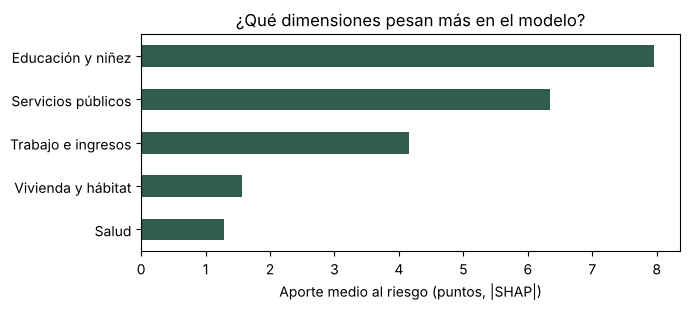

In [8]:
imp = pd.Series(np.abs(shap_vals).mean(0), index=PRIVACIONES).groupby(PRIV2DIM).sum().sort_values()
ax = imp.plot.barh(color="#2f5d50", figsize=(7, 3.2))
ax.set_xlabel("Aporte medio al riesgo (puntos, |SHAP|)"); ax.set_title("¿Qué dimensiones pesan más en el modelo?")
plt.tight_layout(); plt.show()

## 6. Índice de riesgo por subregión
El **índice de riesgo (0–100)** es el porcentaje estimado de personas en pobreza multidimensional. El de cada subregión es el
**promedio de sus municipios**: cada territorio cuenta igual, sin importar su tamaño, coherente con un enfoque de equidad territorial.
Como SHAP es aditivo, los aportes por dimensión de la subregión también son el promedio de los de sus municipios.

In [9]:
ant = df[df["ID"].str.startswith("05")].copy()
cols_dim = ["SHAP " + d for d in DIMENSIONES]
sub = ant.groupby("Subregion").agg(Riesgo=("Riesgo", "mean"), IPM_real=("IPM", "mean"), Base=("Base", "mean"),
                                   Municipios=("ID", "size"), **{c: (c, "mean") for c in cols_dim})
sub = sub.sort_values("Riesgo", ascending=False)
sub.round(1)

,Riesgo,IPM_real,Base,Municipios,SHAP Vivienda y hábitat,SHAP Educación y niñez,SHAP Salud,SHAP Servicios públicos,SHAP Trabajo e ingresos
Subregion,,,,,,,,,
Bajo Cauca,55.1,54.8,41.7,6,1.7,7.7,-0.1,3.7,0.4
Urabá,54.3,55.5,41.9,11,1.0,5.5,-0.0,4.8,1.1
Nordeste,43.4,42.3,41.8,10,-0.7,2.2,-0.7,4.9,-4.0
Occidente,42.5,43.2,41.9,19,-0.7,3.0,-0.5,1.5,-2.6
Norte,40.8,40.3,41.7,17,-1.4,1.7,-0.3,2.3,-3.2
Suroeste,36.8,36.7,41.9,23,-1.7,2.3,-0.5,-0.7,-4.5
Magdalena Medio,36.3,35.4,41.8,6,-0.8,0.2,-0.2,-1.1,-3.7
Oriente,28.1,28.4,41.8,23,-1.9,-2.9,-0.7,-3.9,-4.3
Valle de Aburrá,11.7,12.0,41.7,10,-2.0,-13.1,0.0,-7.8,-7.1


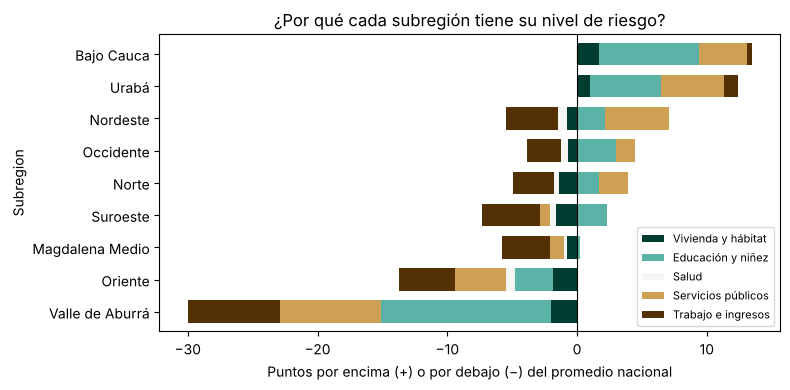

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
s = sub[cols_dim].rename(columns=lambda c: c[5:])
s.iloc[::-1].plot.barh(stacked=True, ax=ax, colormap="BrBG_r", width=.7)
ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Puntos por encima (+) o por debajo (−) del promedio nacional")
ax.set_title("¿Por qué cada subregión tiene su nivel de riesgo?"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

## 7. Exportar para el mapa web

In [11]:
r = lambda v: round(float(v), 1)
MENORES = {"de", "del", "la", "las", "los", "el", "y"}
nombre_bonito = lambda n: " ".join(w if i and w in MENORES else w.capitalize() for i, w in enumerate(n.lower().split()))
salida = {
  "fuente": "DANE — Medida de pobreza multidimensional municipal de fuente censal, CNPV 2018",
  "modelo": MEJOR,
  "metricas": {k: {c: r(v) if "Error" in c else round(float(v), 3) for c, v in fila.items()}
               for k, fila in tabla.to_dict("index").items()},
  "promedio_nacional": r(base.mean()),
  "dimensiones": {d: ps for d, ps in DIMENSIONES.items()},
  "importancia": {d: r(v) for d, v in imp.sort_values(ascending=False).items()},
  "subregiones": [{"nombre": n, "riesgo": r(f.Riesgo), "ipm_real": r(f.IPM_real), "base": r(f.Base),
                   "municipios": int(f.Municipios),
                   "aportes": {d: r(f["SHAP " + d]) for d in DIMENSIONES}} for n, f in sub.iterrows()],
  "municipios": [{"id": f.ID, "nombre": nombre_bonito(f.Municipio), "subregion": f.Subregion, "riesgo": r(f.Riesgo),
                  "ipm_real": r(f.IPM), "base": r(f.Base), "aportes": {d: r(f["SHAP " + d]) for d in DIMENSIONES}}
                 for _, f in ant.sort_values("Riesgo", ascending=False).iterrows()],
}
with open("resultados_modelo.json", "w", encoding="utf-8") as fh:
    json.dump(salida, fh, ensure_ascii=False, indent=1)
print("Exportado resultados_modelo.json —", len(salida["municipios"]), "municipios,", len(salida["subregiones"]), "subregiones")

Exportado resultados_modelo.json — 125 municipios, 9 subregiones


## 8. Conectar con el mapa
Si `index.html` (el mapa) está en la misma carpeta, esta celda le inyecta los resultados nuevos. Así, cada vez que se reentrene el
modelo (por ejemplo, con datos más recientes), el mapa se actualiza sin tocar su código.

In [12]:
import os, re
MAPA = next((p for p in ["index.html", "mapa_territorios.html"] if os.path.exists(p)), None)
if MAPA:
    html = open(MAPA, encoding="utf-8").read()
    bloque = json.dumps(salida, ensure_ascii=False).replace("</", "<\\/")
    html = re.sub(r'(<script type="application/json" id="datos-modelo">).*?(</script>)',
                  lambda m: m.group(1) + bloque + m.group(2), html, flags=re.S)
    open(MAPA, "w", encoding="utf-8").write(html)
    print("Mapa actualizado con los nuevos resultados")
else:
    print("No se encontró index.html — copien el archivo del mapa a esta carpeta para actualizarlo")

Mapa actualizado con los nuevos resultados


## 9. Límites y uso responsable
- **Apoyo a la decisión, no decisión automática.** El índice ordena prioridades; la asignación de inversión sigue siendo una decisión
  humana, que debe contrastarse con las comunidades y con información local.
- **Datos de 2018.** Es la última medición municipal completa del DANE. En una fase siguiente, el mismo modelo puede alimentarse con
  fuentes más frecuentes (SISBÉN IV, registros administrativos, imágenes satelitales) para estimar el riesgo en años sin censo.
- **Promedios ocultan diferencias.** Un municipio o subregión con riesgo medio puede tener veredas con pobreza muy alta; el anexo del DANE
  muestra brechas grandes entre cabeceras y zonas rurales.
- **Ingresos aproximados.** El censo no mide ingresos; la dimensión usa privaciones laborales como aproximación.